In [1]:
import numpy as np
import os
from itertools import combinations
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve

2026-05-26 21:51:10.659579: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779832270.826817      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779832270.872833      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779832271.281759      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779832271.281818      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779832271.281822      23 computation_placer.cc:177] computation placer alr

<class 'numpy.ndarray'>
(288, 256)


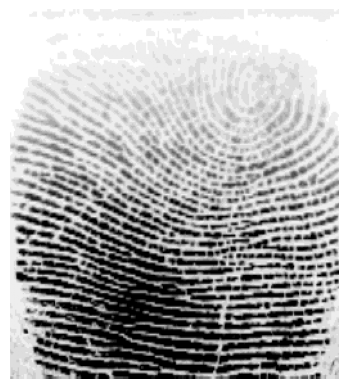

In [3]:
img = cv2.imread(r"/kaggle/input/datasets/torylis/fingers/fingers/6/scan_1.png", cv2.IMREAD_GRAYSCALE)
print(type(img))
print(img.shape)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [4]:
def create_fingerprint_dataset(root_dir, finger_folders):
    A = []
    B = []
    labels = []
    finger_data = {}

    for folder in finger_folders:
        folder_path = os.path.join(root_dir, folder)
        images = []
        for img_name in os.listdir(folder_path):
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (288, 256))
            img = img.astype('float32') / 255.0
            images.append(img.reshape(288, 256, 1))
        finger_data[folder] = images

    for folder in finger_folders:
        imgs = finger_data[folder]
        for img_a, img_b in combinations(imgs, 2):
            A.append(img_a)
            B.append(img_b)
            labels.append(1)

    num_positive = len(labels)
    print(f"Число положительных пар: {num_positive}")

    num_negative = 0
    while num_negative < num_positive:
        f1, f2 = np.random.choice(finger_folders, 2, replace=False)

        len_f1 = len(finger_data[f1])
        len_f2 = len(finger_data[f2])

        img_a = np.random.choice(len_f1)
        img_b = np.random.choice(len_f2)

        A.append(finger_data[f1][img_a])
        B.append(finger_data[f2][img_b])
        labels.append(0)
        num_negative += 1

    print(f"Число отрицательных пар: {num_negative}")

    return np.array(A), np.array(B), np.array(labels)

In [5]:
train_folders = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16']
test_folders = ['17', '18', '19', '20', '21', '22', '23', '24', '25', '26']

In [6]:
X1_train, X2_train, y_train = create_fingerprint_dataset('/kaggle/input/datasets/torylis/fingers/fingers', train_folders)
print(f"Всего пар в train: {len(X1_train)}")
print(f"Размерность X1_train: {X1_train.shape}")

Число положительных пар: 5111
Число отрицательных пар: 5111
Всего пар в train: 10222
Размерность X1_train: (10222, 288, 256, 1)


In [7]:
X1_test, X2_test, y_test = create_fingerprint_dataset('/kaggle/input/datasets/torylis/fingers/fingers', test_folders)
print(f"Всего пар в test: {len(X1_test)}")
print(f"Размерность X1_test: {X1_test.shape}")

Число положительных пар: 571
Число отрицательных пар: 571
Всего пар в test: 1142
Размерность X1_test: (1142, 288, 256, 1)


In [8]:
height, width, depth = 288, 256, 1

def absolute_difference(vectors):
    x, y = vectors
    return tf.abs(x - y)

x1 = layers.Input(shape=(height, width, depth))
x2 = layers.Input(shape=(height, width, depth))

inputs = layers.Input(shape=(height, width, depth))
feature = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
feature = layers.MaxPooling2D(2)(feature)
feature = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D(2)(feature)
feature = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D(2)(feature)
feature = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D(2)(feature)
feature = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D(2)(feature)

feature_model = Model(inputs=inputs, outputs=feature)

x1_net = feature_model(x1)
x2_net = feature_model(x2)

net = layers.Lambda(absolute_difference)([x1_net, x2_net])
net = layers.Flatten()(net)
net = layers.Dense(512, activation='relu')(net)
net = layers.Dense(1, activation='sigmoid')(net)

classifier = Model(inputs=[x1, x2], outputs=net)

classifier.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.Adam(),
    metrics=['accuracy']
)

I0000 00:00:1779832290.293569      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [9]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(
    'our_fingerprint_model.keras',
    monitor='val_loss',
    save_best_only=True
)

In [10]:
history = classifier.fit(
    [X1_train, X2_train], y_train,
    validation_data=([X1_test, X2_test], y_test),
    epochs=20,
    batch_size=16,
    callbacks=[early_stopping, checkpoint],
    verbose=2
)

Epoch 1/20


I0000 00:00:1779832307.473541      69 service.cc:152] XLA service 0x7bfde0011f80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779832307.473607      69 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1779832308.046926      69 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1779832312.985588      69 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


639/639 - 49s - 76ms/step - accuracy: 0.6835 - loss: 0.5899 - val_accuracy: 0.6690 - val_loss: 0.6150
Epoch 2/20
639/639 - 32s - 50ms/step - accuracy: 0.7586 - loss: 0.4809 - val_accuracy: 0.6427 - val_loss: 0.6255
Epoch 3/20
639/639 - 33s - 52ms/step - accuracy: 0.8005 - loss: 0.4136 - val_accuracy: 0.7250 - val_loss: 0.5589
Epoch 4/20
639/639 - 32s - 50ms/step - accuracy: 0.8314 - loss: 0.3671 - val_accuracy: 0.6935 - val_loss: 0.6300
Epoch 5/20
639/639 - 32s - 50ms/step - accuracy: 0.8434 - loss: 0.3434 - val_accuracy: 0.6979 - val_loss: 0.7923
Epoch 6/20
639/639 - 32s - 50ms/step - accuracy: 0.8708 - loss: 0.3022 - val_accuracy: 0.6681 - val_loss: 0.7024
Epoch 7/20
639/639 - 32s - 50ms/step - accuracy: 0.8782 - loss: 0.2845 - val_accuracy: 0.6760 - val_loss: 0.8360
Epoch 8/20
639/639 - 32s - 50ms/step - accuracy: 0.8941 - loss: 0.2516 - val_accuracy: 0.7145 - val_loss: 0.7780
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 3.


36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step
Precision: 0.6980
Recall:    0.7933
ROC AUC:   0.8024


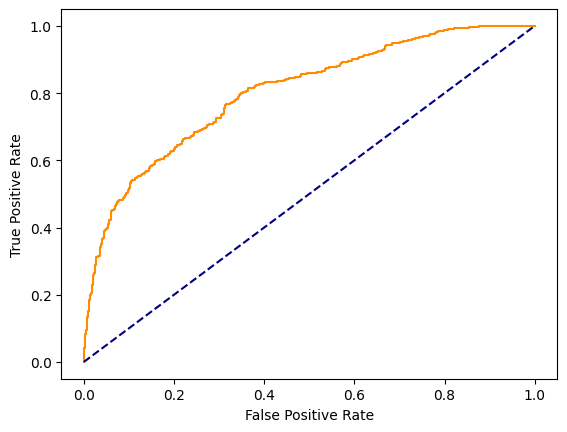

In [11]:
y_pred_prob = classifier.predict([X1_test, X2_test])
y_pred_class = (y_pred_prob > 0.5).astype(int)

prec = precision_score(y_test, y_pred_class)
rec = recall_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred_prob)

print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"ROC AUC:   {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.plot(fpr, tpr, color='darkorange')
plt.plot([0, 1], [0, 1], color='navy', ls='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [12]:
def absolute_difference(vectors):
    x, y = vectors
    return tf.abs(x - y)
classifier = load_model(
    '/kaggle/working/our_fingerprint_model.keras',
    custom_objects={'absolute_difference': absolute_difference}
)

In [13]:
def load_and_preprocess(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (256, 288))
    img = img.astype("float32") / 255.0
    img = np.expand_dims(img, axis=-1)
    img = np.expand_dims(img, axis=0)
    return img

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 894ms/step

Результат сравнения: 0.8679
Палец один и тот же


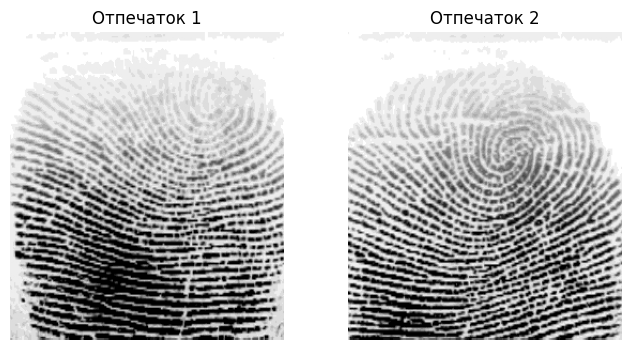

In [14]:
path_1 = r'/kaggle/input/datasets/torylis/fingers/fingers/6/scan_1.png'
path_2 = r'/kaggle/input/datasets/torylis/fingers/fingers/6/scan_2.png'

img1 = load_and_preprocess(path_1)
img2 = load_and_preprocess(path_2)

prediction = classifier.predict([img1, img2])
score = prediction[0][0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1[0, :, :, 0], cmap='gray')
plt.title("Отпечаток 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2[0, :, :, 0], cmap='gray')
plt.title("Отпечаток 2")
plt.axis('off')

print(f"\nРезультат сравнения: {score:.4f}")
if score < 0.5:
    print("Пальцы разные")
else:
    print("Палец один и тот же")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

Результат сравнения: 0.1257
Пальцы разные


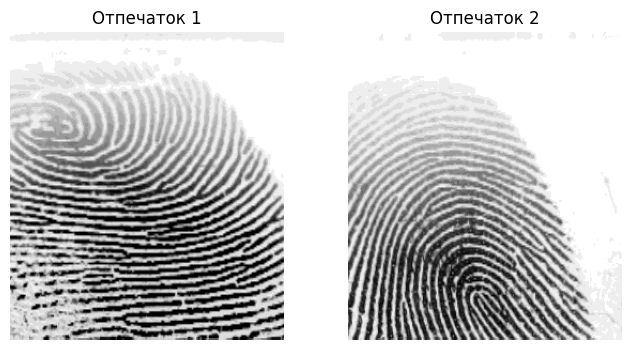

In [15]:
path_1 = r'/kaggle/input/datasets/torylis/fingers/fingers/1/scan_1.png'
path_2 = r'/kaggle/input/datasets/torylis/fingers/fingers/10/scan_1.png'
img1 = load_and_preprocess(path_1)
img2 = load_and_preprocess(path_2)

prediction = classifier.predict([img1, img2])
score = prediction[0][0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1[0, :, :, 0], cmap='gray')
plt.title("Отпечаток 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2[0, :, :, 0], cmap='gray')
plt.title("Отпечаток 2")
plt.axis('off')

print(f"\nРезультат сравнения: {score:.4f}")
if score < 0.5:
    print("Пальцы разные")
else:
    print("Палец один и тот же")

plt.show()